# Figure 5 — Spatial information and ico4 feature contributions to brain-age prediction

Figure 5 focuses on two questions: whether within-region spatial information improves age prediction, and which information at the ico4 scale contributes to prediction gains.

- **A:** complete overview of all 11 representations, ordered from lowest to highest OOF MAE.
- **B:** spatial sequence from the regional 21-depth profile through ico3, ico4, and ico5.
- **C:** ico4 column-mean MD, the full ico4 21-depth representation, and the three geometry extensions.

All metrics and subject-level bootstrap confidence intervals are calculated from the saved OOF predictions for the same 196 participants. The spatial-resolution and ico4-ablation comparison families were organized after inspection of the results and are therefore reported as exploratory/secondary FDR analyses.

## 1. Imports and plotting settings

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import pearsonr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BOOTSTRAP_REPLICATES = 10_000
BOOTSTRAP_SEED = 20261028
QC_TOLERANCE = 1e-6
X_TICK_LABEL_SIZE = 20

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 14, "axes.titlesize": 18,
    "axes.labelsize": 17, "xtick.labelsize": X_TICK_LABEL_SIZE, "ytick.labelsize": 14,
    "axes.linewidth": 1.5, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
})

## 2. File paths, model mapping, and scientific groups

In [2]:
def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "analysis_results/figure5").is_dir():
            return candidate
    raise RuntimeError("Could not locate repository root containing analysis_results/figure5")


REPO_ROOT = find_repo_root()
RESULTS_ROOT = Path("/mnt/newStor/paros/paros_WORK/xintong/results/figure5_age_prediction/outputs")
MODEL_ROOT = RESULTS_ROOT / "models_lsqr"
OUTPUT_DIR = REPO_ROOT / "analysis_results/figure5/outputs/figures"
STATISTICS_DIR = REPO_ROOT / "analysis_results/figure5/outputs/statistics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASE_SUMMARY = RESULTS_ROOT / "summary_lsqr/model_summary.csv"
PROFILE_THICKNESS_SUMMARY = RESULTS_ROOT / "regional_profile_thickness_analysis/model_summary.csv"
GEOMETRY_SUMMARY = RESULTS_ROOT / "ico4_geometry_analysis/ico4_geometry_model_summary.csv"
SUBJECT_ORDER = RESULTS_ROOT / "features/subject_order.csv"
PAIRED_MAE_STATS = STATISTICS_DIR / "Figure5_paired_MAE_comparisons.csv"

MODEL_CONFIG = {
    "regional_mean_md": {"label": "Regional mean MD", "summary": BASE_SUMMARY, "color": "#4D4D4D", "marker": "o"},
    "regional_profile": {"label": "Regional 21-depth profile", "summary": BASE_SUMMARY, "color": "#009E73", "marker": "D"},
    "regional_thickness": {"label": "Regional thickness", "summary": BASE_SUMMARY, "color": "#7F7F7F", "marker": "s"},
    "regional_profile_thickness": {"label": "Regional 21-depth profile + thickness", "summary": PROFILE_THICKNESS_SUMMARY, "color": "#1B9E77", "marker": "P"},
    "ico3_md": {"label": "ico3", "summary": BASE_SUMMARY, "color": "#6BAED6", "marker": "^"},
    "ico4_md": {"label": "ico4", "summary": BASE_SUMMARY, "color": "#D55E00", "marker": "o"},
    "ico5_md": {"label": "ico5", "summary": BASE_SUMMARY, "color": "#3182BD", "marker": "v"},
    "ico4_column_mean_md": {"label": "ico4 column mean MD", "summary": BASE_SUMMARY, "color": "#E69F00", "marker": "*"},
    "ico4_md_length": {"label": "ico4 + length", "summary": GEOMETRY_SUMMARY, "color": "#D73027", "marker": ">"},
    "ico4_md_curvature": {"label": "ico4 + curvature", "summary": GEOMETRY_SUMMARY, "color": "#FDAE61", "marker": "h"},
    "ico4_md_length_curvature": {"label": "ico4 + length + curvature", "summary": GEOMETRY_SUMMARY, "color": "#F46D43", "marker": "X"},
}

PLOT_GROUPS = [
    ("Regional representations", ["regional_mean_md", "regional_profile", "regional_thickness", "regional_profile_thickness"]),
    ("Spatial resolution", ["regional_profile", "ico3_md", "ico4_md", "ico5_md"]),
    ("ico4 feature ablation", ["ico4_column_mean_md", "ico4_md", "ico4_md_length", "ico4_md_curvature", "ico4_md_length_curvature"]),
]
EXPECTED_MAE_ORDER = [
    "ico4_md_length", "ico4_md_length_curvature", "ico4_md", "ico4_md_curvature",
    "ico5_md", "ico4_column_mean_md", "regional_profile_thickness", "regional_profile",
    "ico3_md", "regional_thickness", "regional_mean_md",
]

required_paths = [BASE_SUMMARY, PROFILE_THICKNESS_SUMMARY, GEOMETRY_SUMMARY, SUBJECT_ORDER, PAIRED_MAE_STATS]
required_paths += [MODEL_ROOT / key / f"{key}_oof_predictions.csv" for key in MODEL_CONFIG]
missing = [str(p) for p in required_paths if not p.is_file()]
if missing:
    raise FileNotFoundError("Required Figure 5 inputs are missing:\n" + "\n".join(missing))

print(f"Repository root: {REPO_ROOT}")
print(f"Formal result root: {RESULTS_ROOT}")
print(f"Figure output directory: {OUTPUT_DIR}")

Repository root: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis
Formal result root: /mnt/newStor/paros/paros_WORK/xintong/results/figure5_age_prediction/outputs
Figure output directory: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure5/outputs/figures


## 2A. Statistics for selected data and review pools

This section reports the six requested all-diagnosis pools and deliberately omits the current final 196-subject CN group: all metadata (N=448), complete Option 3 DWI (N=325), QC-passed analyzable DWI reference (N=320), no-observed-label-conflict candidates after coverage QC (N=259), the different-label review subset (N=54), and their All-QIAL all-label union (N=313). Normal, MCI, AD, Other/Impaired, and Unknown labels all remain in scope. The review groups are descriptive candidates only; models were not rerun.

For the 448-person metadata pool, age, diagnosis, and QIAL confidence are available for 369 subjects, while visit audit and profile coverage are available for the 325-person complete-DWI pool. In the QC-passed 320-person reference, 266 have no observed label conflict and 54 require different-label review; seven of the 266 fail 95% coverage, yielding 259 + 54 = 313. Missing values are shown explicitly and all percentages use the total N of each displayed pool.

`SUBJECT_SEX` codes are reported as stored because their codebook has not been verified. The generated selected-pool tables are stored under `analysis_results/figure5/cohort_selection/outputs/rule_statistics/selected_pool_*.csv`.

In [ ]:
RULE_STATISTICS_DIR = REPO_ROOT / 'analysis_results/figure5/cohort_selection/outputs/rule_statistics'
SELECTED_DEFINITIONS = RULE_STATISTICS_DIR / 'selected_pool_definitions.csv'
SELECTED_SUMMARY = RULE_STATISTICS_DIR / 'selected_pool_summary.csv'
SELECTED_GROUP_COUNTS = RULE_STATISTICS_DIR / 'selected_pool_group_counts.csv'
SELECTED_AGE_BANDS = RULE_STATISTICS_DIR / 'selected_pool_age_band_counts.csv'

missing_pool_files = [str(path) for path in [SELECTED_DEFINITIONS, SELECTED_SUMMARY, SELECTED_GROUP_COUNTS, SELECTED_AGE_BANDS] if not path.is_file()]
if missing_pool_files:
    raise FileNotFoundError('Missing selected-pool statistics; run build_selected_pool_statistics.py:\n' + '\n'.join(missing_pool_files))

selected_pool_definitions = pd.read_csv(SELECTED_DEFINITIONS)
selected_pool_summary = pd.read_csv(SELECTED_SUMMARY)
selected_pool_group_counts = pd.read_csv(SELECTED_GROUP_COUNTS)
selected_pool_age_bands = pd.read_csv(SELECTED_AGE_BANDS)

display(Markdown('### Selected pool definitions'))
display(selected_pool_definitions[['pool_label', 'n_subjects', 'definition']])

display(Markdown('### Demographic and match summary'))
summary_columns = [
    'pool_label', 'n_subjects', 'age_n', 'age_missing_n', 'age_mean', 'age_sd', 'age_median', 'age_q25', 'age_q75',
    'sex_code_1_n', 'sex_code_2_n', 'sex_code_9_n',
    'qial_high_n', 'qial_medium_n', 'qial_low_n', 'qial_ambiguous_n', 'qial_missing_n',
    'visit_audit_n', 'visit_audit_missing_n', 'coverage_n', 'coverage_missing_n', 'coverage_mean', 'coverage_min',
]
display(selected_pool_summary[summary_columns].round(2))

display(Markdown('### Age bands (years)'))
display(selected_pool_age_bands.pivot(index='pool_label', columns='age_band', values='n').reset_index())

for variable in ['QIAL match confidence', 'Matched-visit diagnosis', 'SUBJECT_SEX code', 'Number of distinct visit dates', 'Longitudinal diagnosis audit', 'Profile coverage status']:
    display(Markdown(f'### {variable}'))
    display(selected_pool_group_counts.loc[selected_pool_group_counts['variable'].eq(variable)].reset_index(drop=True))

## 3. Read model summaries and OOF predictions

In [3]:
summary_tables = {p: pd.read_csv(p) for p in {c["summary"] for c in MODEL_CONFIG.values()}}
subject_order = pd.read_csv(SUBJECT_ORDER)
required_subject_columns = {"row_index", "subject_id", "age_at_scan"}
if not required_subject_columns.issubset(subject_order.columns):
    raise RuntimeError(f"subject_order.csv lacks columns: {required_subject_columns - set(subject_order.columns)}")
if subject_order["row_index"].duplicated().any() or subject_order["subject_id"].duplicated().any():
    raise RuntimeError("subject_order.csv contains duplicate row_index or subject_id values")

summary_rows, predictions = [], {}
for key, config in MODEL_CONFIG.items():
    matched = summary_tables[config["summary"]].loc[lambda x: x["representation"].eq(key)]
    if len(matched) != 1:
        raise RuntimeError(f"Expected exactly one summary row for {key}; found {len(matched)}")
    row = matched.iloc[0]
    summary_rows.append({
        "representation": key, "model": config["label"], "summary_n": int(row["n"]),
        "summary_mae": float(row["mae"]), "summary_pearson_r": float(row["pearson_r"]),
        "summary_source": str(config["summary"]),
    })
    p = MODEL_ROOT / key / f"{key}_oof_predictions.csv"
    frame = pd.read_csv(p)
    required = {"row_index", "true_age", "predicted_age"}
    if not required.issubset(frame.columns):
        raise RuntimeError(f"{p} lacks columns: {required - set(frame.columns)}")
    frame = (frame[["row_index", "true_age", "predicted_age"]]
             .merge(subject_order[["row_index", "subject_id", "age_at_scan"]],
                    on="row_index", how="left", validate="one_to_one")
             .sort_values("row_index").reset_index(drop=True))
    predictions[key] = frame

summary_df = pd.DataFrame(summary_rows).set_index("representation")
summary_df

,model,summary_n,summary_mae,summary_pearson_r,summary_source
representation,,,,,
regional_mean_md,Regional mean MD,196,6.080992,0.661741,/mnt/newStor/paros/paros_WORK/xintong/results/...
regional_profile,Regional 21-depth profile,196,5.638254,0.717386,/mnt/newStor/paros/paros_WORK/xintong/results/...
regional_thickness,Regional thickness,196,5.989418,0.698314,/mnt/newStor/paros/paros_WORK/xintong/results/...
regional_profile_thickness,Regional 21-depth profile + thickness,196,5.579632,0.732607,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico3_md,ico3,196,5.686713,0.716631,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico4_md,ico4,196,5.290518,0.761166,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico5_md,ico5,196,5.363515,0.757462,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico4_column_mean_md,ico4 column mean MD,196,5.440511,0.741245,/mnt/newStor/paros/paros_WORK/xintong/results/...
ico4_md_length,ico4 + length,196,5.233371,0.769829,/mnt/newStor/paros/paros_WORK/xintong/results/...


## 4. Subject and result QC

In [4]:
if len(MODEL_CONFIG) != 11 or set(MODEL_CONFIG) != set(EXPECTED_MAE_ORDER):
    raise RuntimeError("Model mapping does not contain exactly the 11 requested representations")
if set(k for _, keys in PLOT_GROUPS for k in keys) != set(MODEL_CONFIG):
    raise RuntimeError("Scientific plot groups do not cover all 11 representations")

reference = predictions["regional_mean_md"]
if len(reference) != 196:
    raise RuntimeError(f"Expected 196 subjects; found {len(reference)}")

qc_rows = []
for key, frame in predictions.items():
    if len(frame) != 196:
        raise RuntimeError(f"{key}: expected 196 OOF predictions; found {len(frame)}")
    if frame["row_index"].duplicated().any() or frame["subject_id"].duplicated().any():
        raise RuntimeError(f"{key}: duplicate subject or row_index")
    if frame[["true_age", "predicted_age", "subject_id"]].isna().any().any():
        raise RuntimeError(f"{key}: missing subject ID, true age, or prediction")
    if not np.array_equal(frame["subject_id"].to_numpy(), reference["subject_id"].to_numpy()):
        raise RuntimeError(f"{key}: subject IDs/order differ after row-index merge")
    if not np.allclose(frame["true_age"], reference["true_age"], atol=0, rtol=0):
        raise RuntimeError(f"{key}: true ages differ from reference")
    if not np.allclose(frame["true_age"], frame["age_at_scan"], atol=0, rtol=0):
        raise RuntimeError(f"{key}: true ages disagree with subject_order.csv")

    y_true = frame["true_age"].to_numpy(float)
    y_pred = frame["predicted_age"].to_numpy(float)
    values = {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "pearson_r": float(pearsonr(y_true, y_pred).statistic),
        "r2": float(r2_score(y_true, y_pred)),
    }
    mae_diff = abs(values["mae"] - summary_df.loc[key, "summary_mae"])
    r_diff = abs(values["pearson_r"] - summary_df.loc[key, "summary_pearson_r"])
    if summary_df.loc[key, "summary_n"] != 196 or mae_diff >= QC_TOLERANCE or r_diff >= QC_TOLERANCE:
        raise RuntimeError(f"{key}: recalculated metrics disagree with saved summary (MAE diff={mae_diff:.3g}, r diff={r_diff:.3g})")
    qc_rows.append({"representation": key, "model": MODEL_CONFIG[key]["label"], "n": 196, **values,
                    "mae_abs_difference": mae_diff, "pearson_r_abs_difference": r_diff})

qc_df = pd.DataFrame(qc_rows)
actual_order = qc_df.sort_values("mae")["representation"].tolist()
if actual_order != EXPECTED_MAE_ORDER:
    raise RuntimeError(f"Unexpected MAE rank order:\n{actual_order}")

print("QC PASSED: 11 models × 196 unique matched subjects; ages and saved metrics agree.")
display(qc_df.set_index("representation").loc[EXPECTED_MAE_ORDER].reset_index())

QC PASSED: 11 models × 196 unique matched subjects; ages and saved metrics agree.


,representation,model,n,mae,rmse,pearson_r,r2,mae_abs_difference,pearson_r_abs_difference
0,ico4_md_length,ico4 + length,196,5.233371,6.850516,0.769829,0.574227,0.0,0.000000e+00
1,ico4_md_length_curvature,ico4 + length + curvature,196,5.246867,6.850627,0.770821,0.574213,0.0,0.000000e+00
2,ico4_md,ico4,196,5.290518,6.938888,0.761166,0.563171,0.0,0.000000e+00
3,ico4_md_curvature,ico4 + curvature,196,5.298498,6.935460,0.762435,0.563603,0.0,1.110223e-16
4,ico5_md,ico5,196,5.363515,6.992468,0.757462,0.556399,0.0,1.110223e-16
5,ico4_column_mean_md,ico4 column mean MD,196,5.440511,7.099988,0.741245,0.542652,0.0,1.110223e-16
6,regional_profile_thickness,Regional 21-depth profile + thickness,196,5.579632,7.160148,0.732607,0.534869,0.0,0.000000e+00
7,regional_profile,Regional 21-depth profile,196,5.638254,7.314238,0.717386,0.514634,0.0,0.000000e+00
8,ico3_md,ico3,196,5.686713,7.376824,0.716631,0.506292,0.0,0.000000e+00
9,regional_thickness,Regional thickness,196,5.989418,7.515863,0.698314,0.487506,0.0,0.000000e+00


## 5. Subject-level bootstrap CIs for MAE, RMSE, Pearson r, and R²

In [5]:
rng = np.random.default_rng(BOOTSTRAP_SEED)
n_subjects = len(reference)
bootstrap_indices = rng.integers(0, n_subjects, size=(BOOTSTRAP_REPLICATES, n_subjects))
true_age = reference["true_age"].to_numpy(float)
boot_true = true_age[bootstrap_indices]
boot_true_centered = boot_true - boot_true.mean(axis=1, keepdims=True)
boot_true_ss = np.sum(boot_true_centered ** 2, axis=1)
if np.any(boot_true_ss == 0):
    raise RuntimeError("A bootstrap sample has zero true-age variance")

point_table = qc_df.set_index("representation")
ci_rows = []
for key in MODEL_CONFIG:
    predicted = predictions[key]["predicted_age"].to_numpy(float)
    residual = predicted - true_age
    boot_residual = residual[bootstrap_indices]
    boot_mae = np.mean(np.abs(boot_residual), axis=1)
    boot_rmse = np.sqrt(np.mean(boot_residual ** 2, axis=1))
    boot_predicted = predicted[bootstrap_indices]
    boot_pred_centered = boot_predicted - boot_predicted.mean(axis=1, keepdims=True)
    denom = np.sqrt(boot_true_ss * np.sum(boot_pred_centered ** 2, axis=1))
    if np.any(denom == 0):
        raise RuntimeError(f"{key}: zero variance in bootstrap Pearson-r sample")
    boot_r = np.sum(boot_true_centered * boot_pred_centered, axis=1) / denom
    boot_r2 = 1.0 - np.sum(boot_residual ** 2, axis=1) / boot_true_ss
    for metric, boot_values in (("mae", boot_mae), ("rmse", boot_rmse), ("pearson_r", boot_r), ("r2", boot_r2)):
        lower, upper = np.percentile(boot_values, [2.5, 97.5])
        ci_rows.append({
            "representation": key, "model": MODEL_CONFIG[key]["label"], "metric": metric,
            "estimate": float(point_table.loc[key, metric]), "ci95_lower": float(lower),
            "ci95_upper": float(upper), "n_subjects": n_subjects,
            "bootstrap_replicates": BOOTSTRAP_REPLICATES, "bootstrap_seed": BOOTSTRAP_SEED,
            "bootstrap_unit": "subject", "interval_method": "percentile",
        })

metric_ci = pd.DataFrame(ci_rows)
metric_ci.to_csv(OUTPUT_DIR / "Figure5_all_metrics_bootstrap_ci.csv", index=False)
print(f"Computed {len(metric_ci)} metric intervals using one shared subject-index matrix.")
display(metric_ci.head())

Computed 44 metric intervals using one shared subject-index matrix.


,representation,model,metric,estimate,ci95_lower,ci95_upper,n_subjects,bootstrap_replicates,bootstrap_seed,bootstrap_unit,interval_method
0,regional_mean_md,Regional mean MD,mae,6.080992,5.410109,6.793417,196,10000,20261028,subject,percentile
1,regional_mean_md,Regional mean MD,rmse,7.902251,7.039709,8.786864,196,10000,20261028,subject,percentile
2,regional_mean_md,Regional mean MD,pearson_r,0.661741,0.586737,0.732348,196,10000,20261028,subject,percentile
3,regional_mean_md,Regional mean MD,r2,0.433457,0.310578,0.531032,196,10000,20261028,subject,percentile
4,regional_profile,Regional 21-depth profile,mae,5.638254,5.009890,6.307636,196,10000,20261028,subject,percentile


## 6. Prepare plotting data and statistical annotations

In [6]:
plot_data = metric_ci.copy()
plot_data["color"] = plot_data["representation"].map(lambda k: MODEL_CONFIG[k]["color"])
plot_data["marker"] = plot_data["representation"].map(lambda k: MODEL_CONFIG[k]["marker"])
plot_data["mae_rank"] = plot_data["representation"].map({k: i + 1 for i, k in enumerate(EXPECTED_MAE_ORDER)})
plot_data.to_csv(OUTPUT_DIR / "Figure5_plot_data.csv", index=False)

paired_stats = pd.read_csv(PAIRED_MAE_STATS)
expected_family_sizes = {"spatial_resolution": 3, "ico4_ablation": 4}
if paired_stats.groupby("family").size().to_dict() != expected_family_sizes:
    raise RuntimeError("Exploratory FDR table does not contain the expected 3+4 comparison families")
if paired_stats["fdr_bh_q"].isna().any():
    raise RuntimeError("Every comparison in the two exploratory FDR families must have a q value")

def exactly_one(a, b):
    match = paired_stats.loc[
        paired_stats["representation_a"].eq(a) & paired_stats["representation_b"].eq(b)
    ]
    if len(match) != 1:
        raise RuntimeError(f"Expected one saved comparison for {a} vs {b}; found {len(match)}")
    return match.iloc[0]

rp_ico4 = exactly_one("regional_profile", "ico4_md")
ico4_ico5 = exactly_one("ico4_md", "ico5_md")
column_ico4 = exactly_one("ico4_column_mean_md", "ico4_md")
ico4_length = exactly_one("ico4_md", "ico4_md_length")

paired_stats.to_csv(OUTPUT_DIR / "Figure5_exploratory_FDR_statistics.csv", index=False)
display_stats = paired_stats.loc[
    paired_stats["comparison"].isin([
        "Regional 21-depth profile − ico4", "ico4 − ico5",
        "ico4 column mean MD − ico4", "ico4 − ico4 + length",
    ])
].copy()
display_stats.to_csv(OUTPUT_DIR / "Figure5_displayed_MAE_statistics.csv", index=False)
display(paired_stats[["family", "comparison", "delta_mae_a_minus_b", "ci95_lower", "ci95_upper",
                      "bootstrap_two_sided_p", "fdr_bh_q"]])

,family,comparison,delta_mae_a_minus_b,ci95_lower,ci95_upper,bootstrap_two_sided_p,fdr_bh_q
0,spatial_resolution,Regional 21-depth profile − ico3,-0.048459,-0.394110,0.291609,0.775322,0.775322
1,spatial_resolution,Regional 21-depth profile − ico4,0.347735,0.057046,0.665469,0.021598,0.064794
2,spatial_resolution,ico4 − ico5,-0.072997,-0.175077,0.027488,0.158584,0.237876
3,ico4_ablation,ico4 column mean MD − ico4,0.149993,-0.057946,0.364215,0.161984,0.237310
4,ico4_ablation,ico4 − ico4 + length,0.057147,-0.000321,0.115386,0.053595,0.214379
5,ico4_ablation,ico4 − ico4 + curvature,-0.007980,-0.034948,0.018133,0.539946,0.539946
6,ico4_ablation,ico4 − ico4 + length + curvature,0.043651,-0.018046,0.107524,0.177982,0.237310


## 7. Figure 5A: complete 11-model MAE overview

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


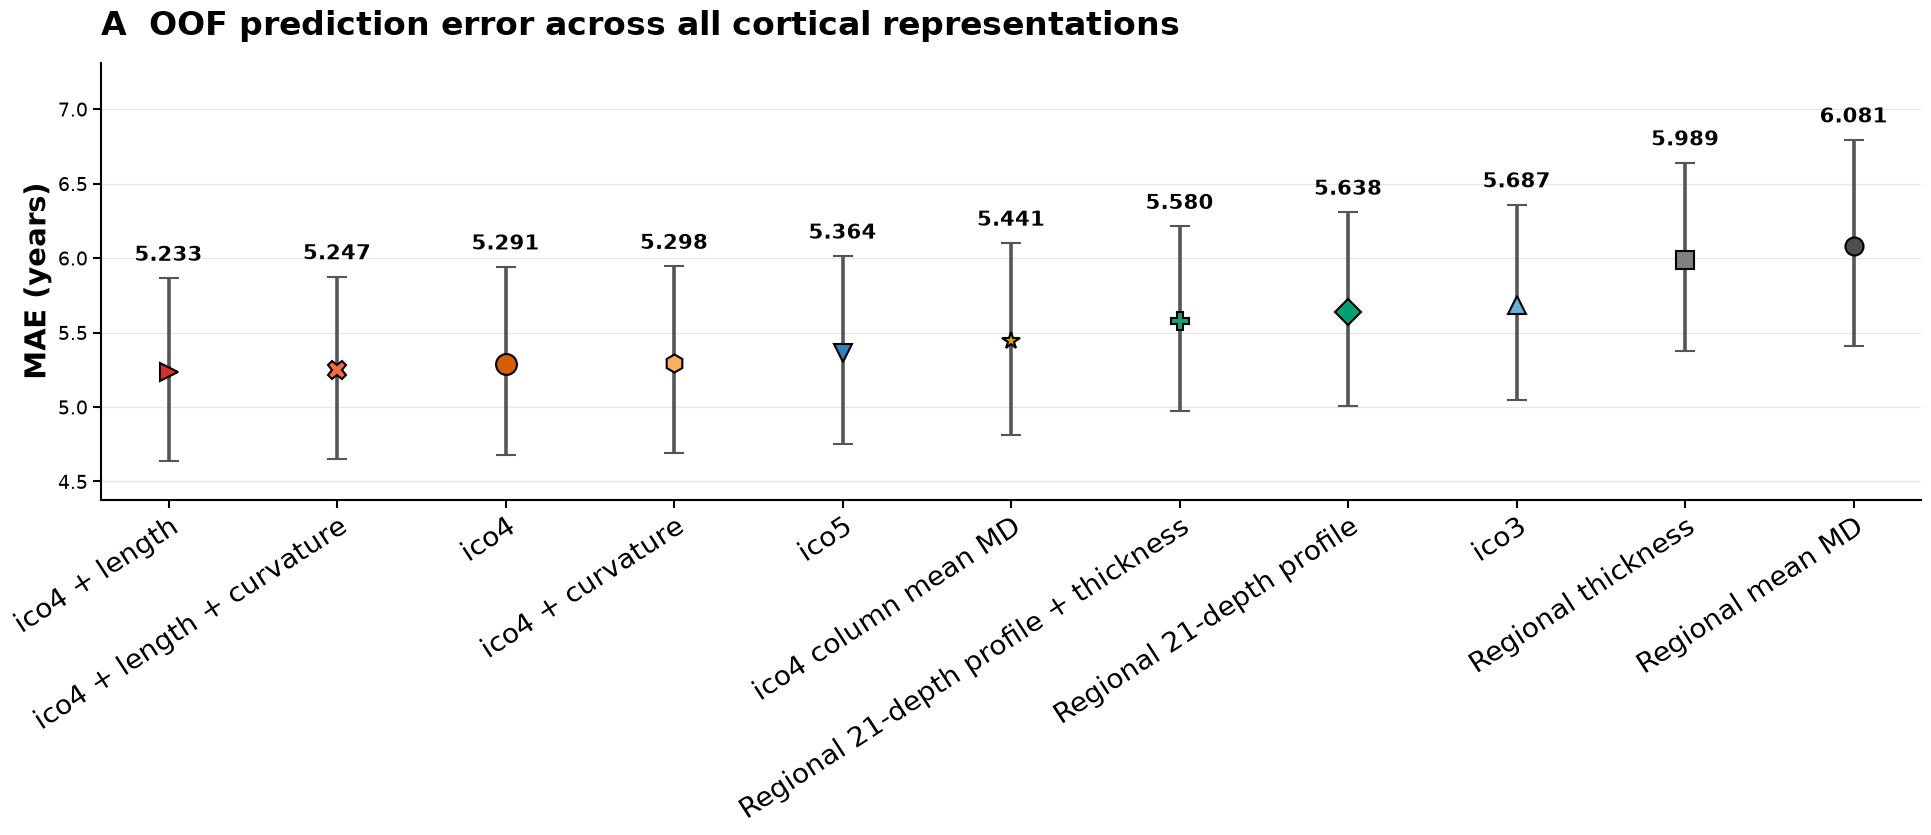

In [7]:
ERROR_COLOR = "#555555"
AXIS_LINEWIDTH = 1.8

def save_figure(fig, stem):
    for suffix in ("png", "pdf", "svg"):
        kwargs = {"dpi": 600} if suffix == "png" else {}
        fig.savefig(OUTPUT_DIR / f"{stem}.{suffix}", bbox_inches="tight", facecolor="white", **kwargs)

def draw_metric_points(ax, keys, metric, value_labels=True):
    rows = metric_ci.loc[metric_ci["metric"].eq(metric)].set_index("representation")
    x = np.arange(len(keys))
    for xpos, key in zip(x, keys):
        row = rows.loc[key]
        config = MODEL_CONFIG[key]
        ax.errorbar(
            xpos, row["estimate"],
            yerr=[[row["estimate"] - row["ci95_lower"]], [row["ci95_upper"] - row["estimate"]]],
            fmt=config["marker"], markersize=13 if key != "ico4_md" else 15,
            markerfacecolor=config["color"], markeredgecolor="black", markeredgewidth=1.5,
            ecolor=ERROR_COLOR, elinewidth=2.6, capsize=7, capthick=2.3, zorder=3,
        )
        if value_labels:
            ax.annotate(f"{row['estimate']:.3f}", (xpos, row["ci95_upper"]), xytext=(0, 9),
                        textcoords="offset points", ha="center", va="bottom",
                        fontsize=15, fontweight="semibold")
    ax.set_xticks(x, [MODEL_CONFIG[k]["label"] for k in keys], rotation=33, ha="right", rotation_mode="anchor",
                  fontsize=X_TICK_LABEL_SIZE)
    ax.grid(axis="y", color="#D9D9D9", linewidth=0.9, alpha=0.65)
    ax.tick_params(axis="both", width=1.5, length=6)
    ax.margins(x=0.04)
    return rows

fig, ax = plt.subplots(figsize=(20, 9.5))
mae_rows = draw_metric_points(ax, EXPECTED_MAE_ORDER, "mae")
low, high = mae_rows["ci95_lower"].min(), mae_rows["ci95_upper"].max()
span = high - low
ax.set_ylim(low - 0.12 * span, high + 0.24 * span)
ax.set_ylabel("MAE (years)", fontsize=21, fontweight="semibold")
ax.set_title("A  OOF prediction error across all cortical representations", loc="left",
             fontsize=24, fontweight="bold", pad=20)
fig.subplots_adjust(left=0.075, right=0.985, bottom=0.40, top=0.86)
save_figure(fig, "Figure5A_MAE")
plt.show()
fig_mae_overview = fig

## 8. Figure 5B and 5C: focused MAE comparisons

findfont: Failed to find font weight semibold, now using 700.


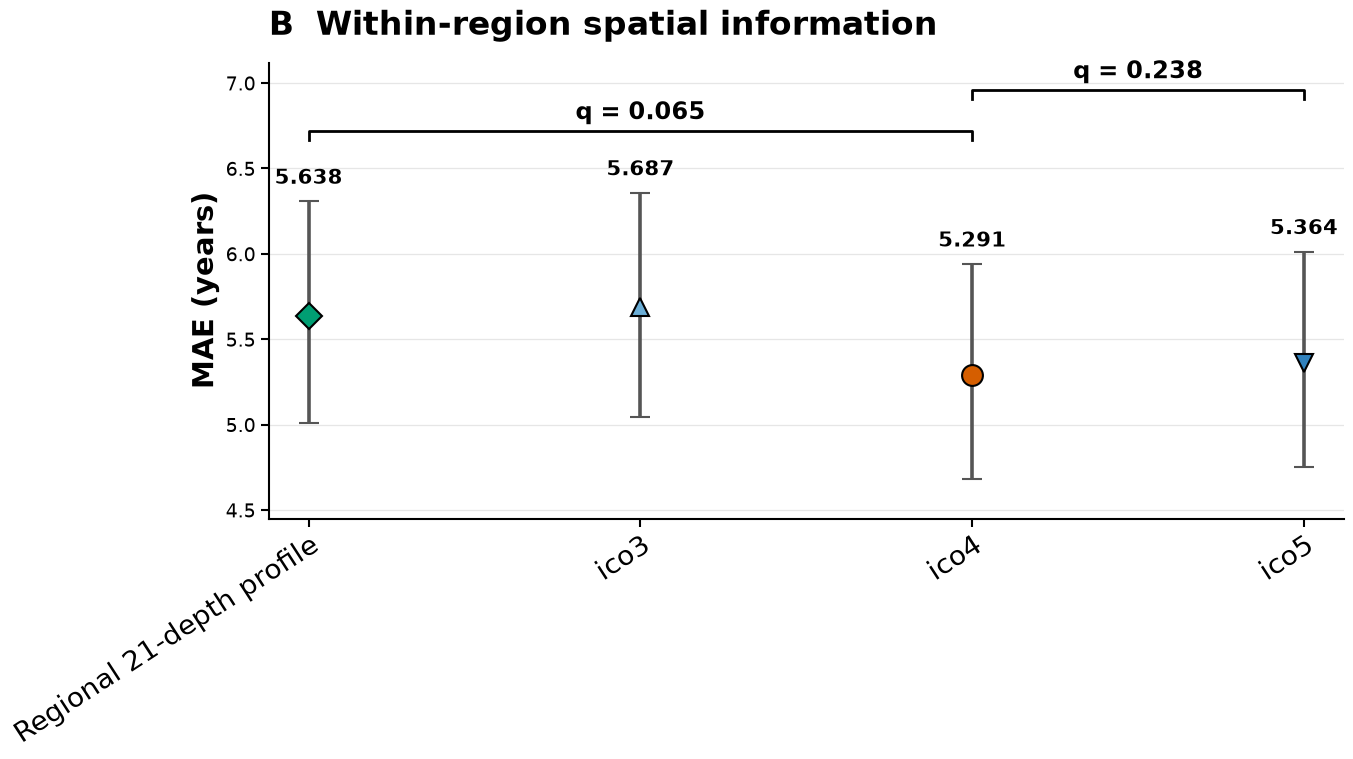

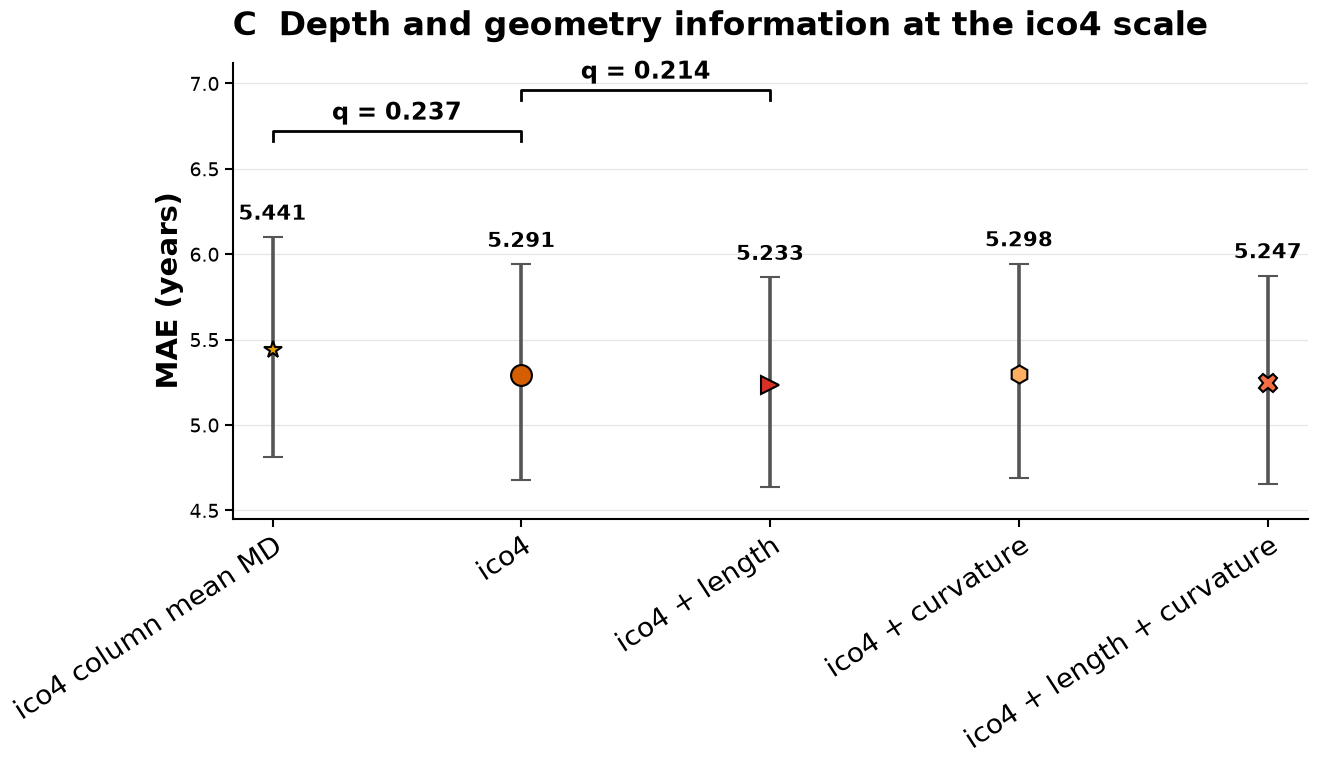

In [8]:
SPATIAL_KEYS = ["regional_profile", "ico3_md", "ico4_md", "ico5_md"]
ICO4_KEYS = ["ico4_column_mean_md", "ico4_md", "ico4_md_length", "ico4_md_curvature", "ico4_md_length_curvature"]
FOCUS_YLIM = (4.45, 7.12)

def add_bracket(ax, x1, x2, y, text):
    height = 0.055
    ax.plot([x1, x1, x2, x2], [y - height, y, y, y - height], color="black", linewidth=2.0, clip_on=False)
    ax.text((x1 + x2) / 2, y + 0.035, text, ha="center", va="bottom", fontsize=17, fontweight="semibold")

def draw_focus_panel(keys, title, stem, annotations):
    fig, ax = plt.subplots(figsize=(12.5, 9.5))
    draw_metric_points(ax, keys, "mae")
    ax.set_ylim(*FOCUS_YLIM)
    ax.set_ylabel("MAE (years)", fontsize=21, fontweight="semibold")
    ax.set_title(title, loc="left", fontsize=24, fontweight="bold", pad=20)
    for x1, x2, y, text in annotations:
        add_bracket(ax, x1, x2, y, text)
    fig.subplots_adjust(left=0.12, right=0.98, bottom=0.37, top=0.85)
    save_figure(fig, stem)
    plt.show()
    return fig

fig_spatial = draw_focus_panel(
    SPATIAL_KEYS,
    "B  Within-region spatial information",
    "Figure5B_spatial_resolution_MAE",
    [(0, 2, 6.72, f"q = {rp_ico4['fdr_bh_q']:.3f}"),
     (2, 3, 6.96, f"q = {ico4_ico5['fdr_bh_q']:.3f}")],
)
fig_ico4 = draw_focus_panel(
    ICO4_KEYS,
    "C  Depth and geometry information at the ico4 scale",
    "Figure5C_ico4_features_MAE",
    [(0, 1, 6.72, f"q = {column_ico4['fdr_bh_q']:.3f}"),
     (1, 2, 6.96, f"q = {ico4_length['fdr_bh_q']:.3f}")],
)

## 9. Supplementary overview panels for Pearson r, RMSE, and R²

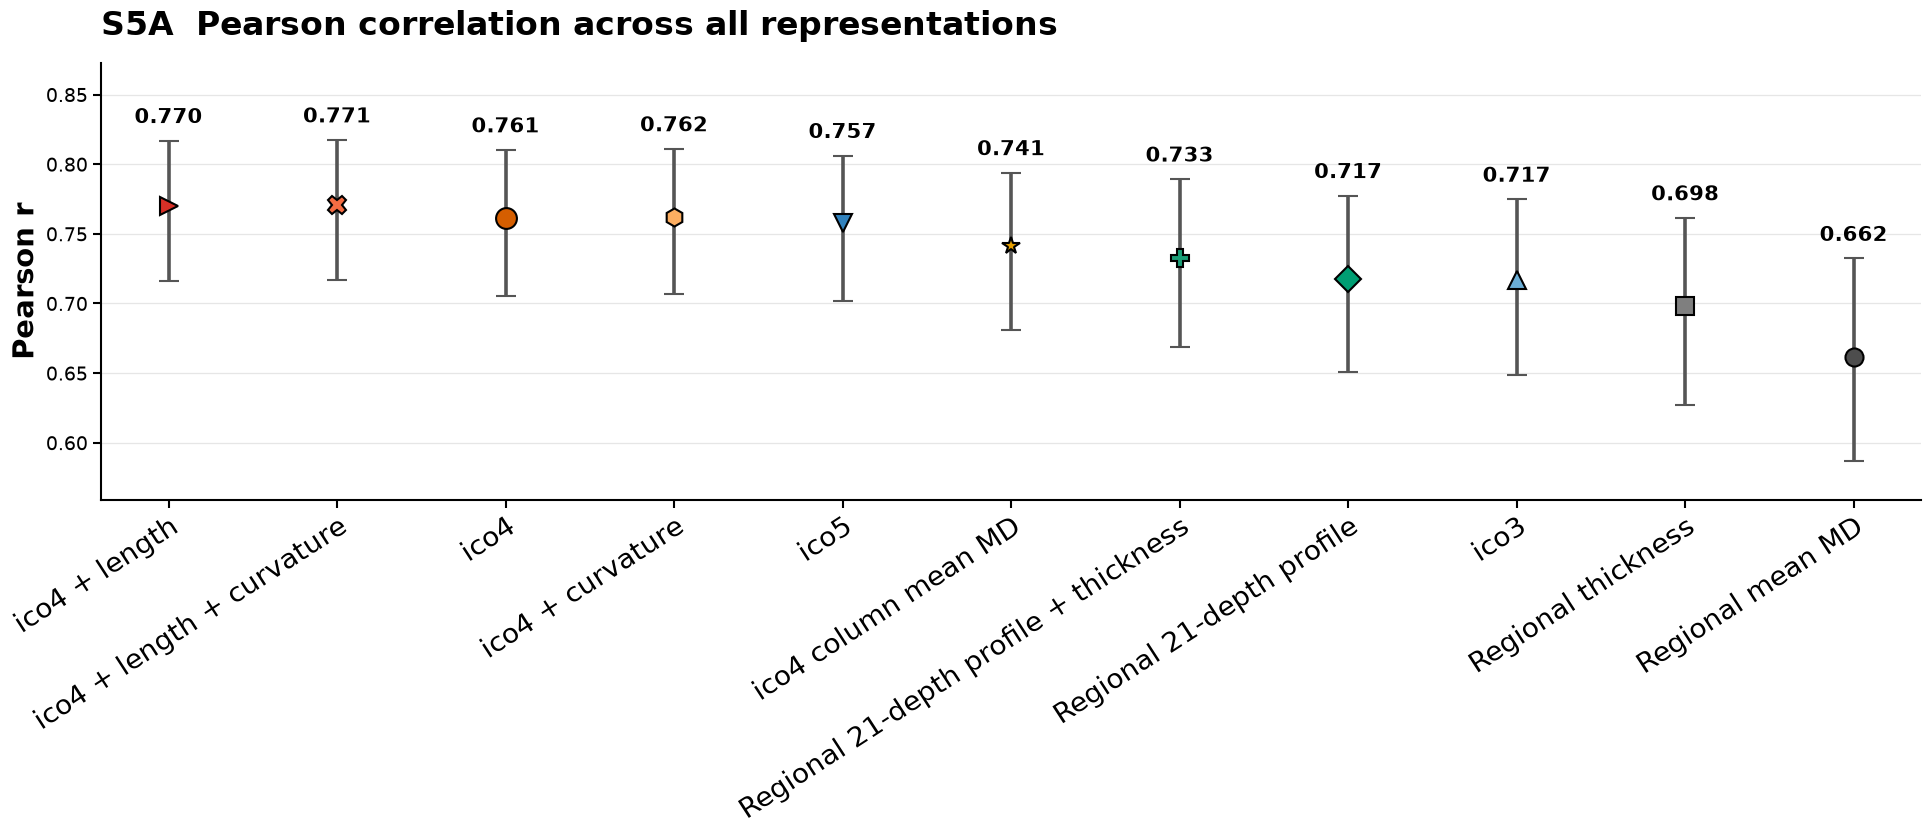

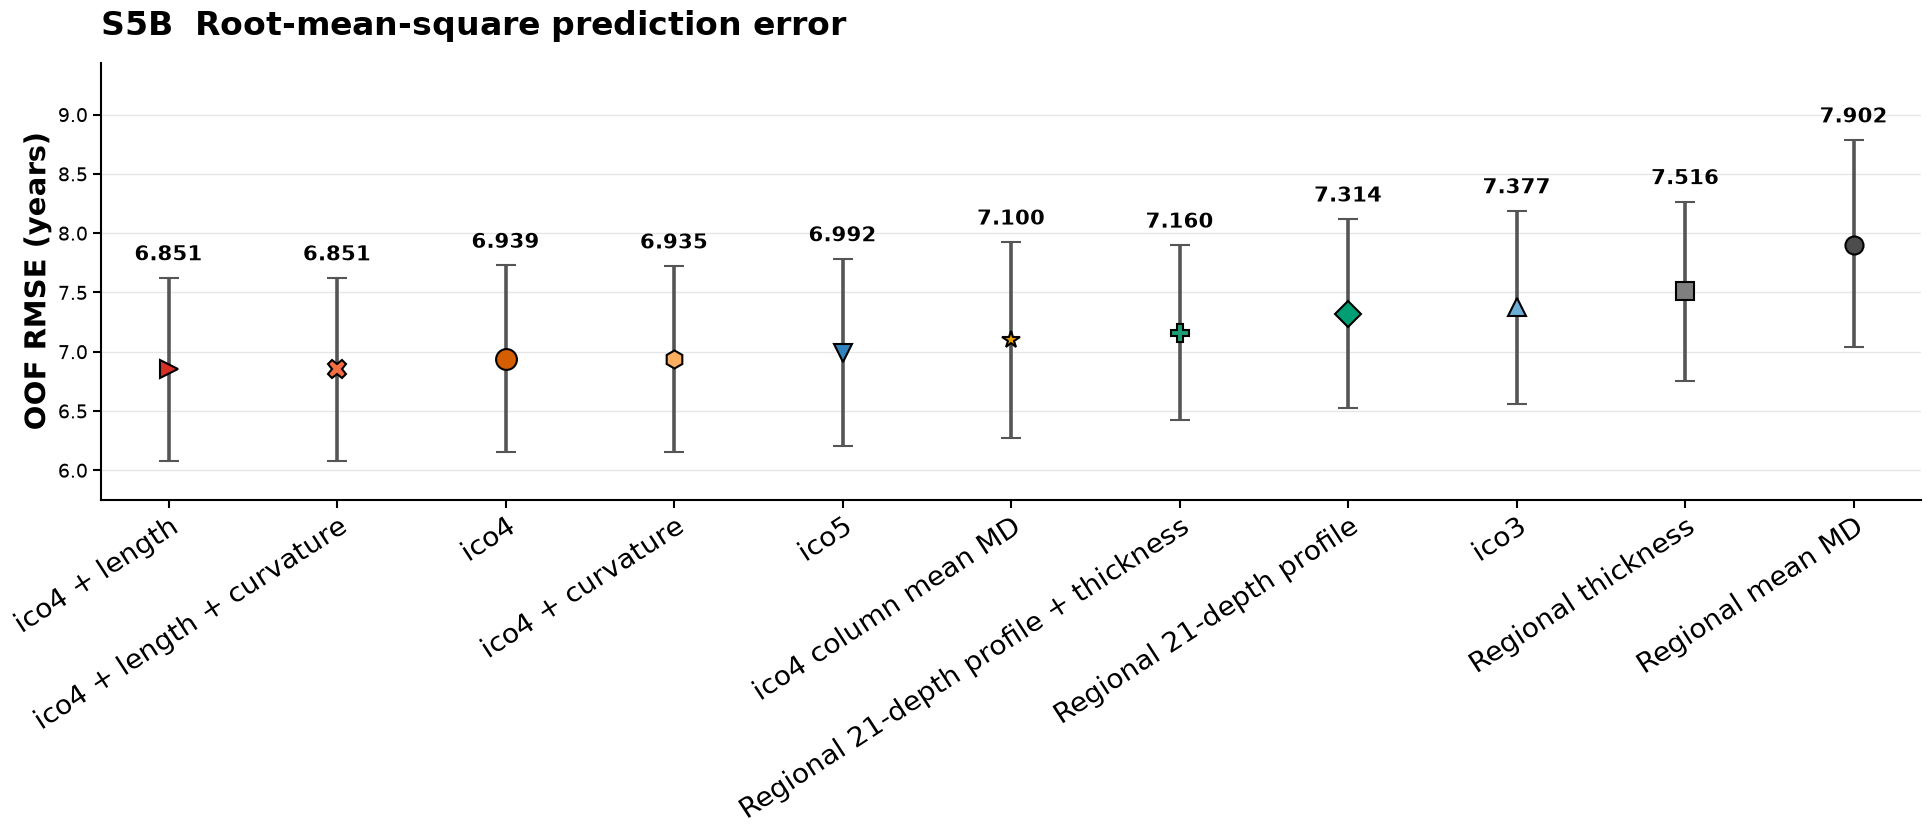

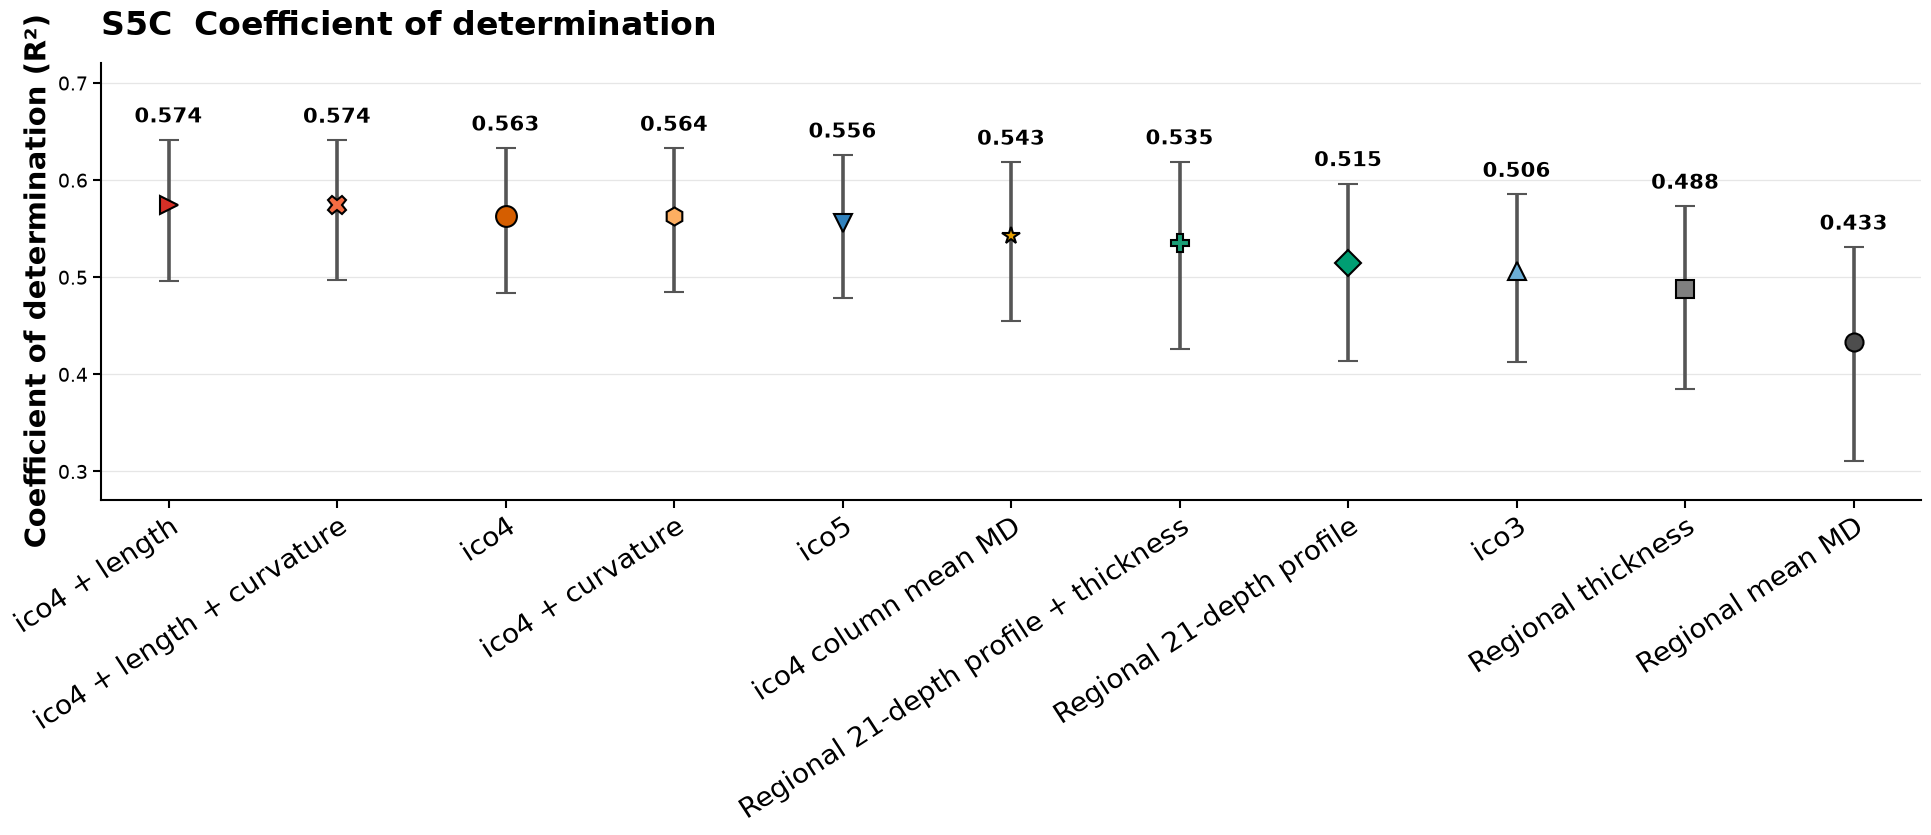

In [9]:
SUPPLEMENT_STYLE = {
    "pearson_r": ("Pearson r", "S5A  Pearson correlation across all representations", "FigureS5A_Pearson_r"),
    "rmse": ("OOF RMSE (years)", "S5B  Root-mean-square prediction error", "FigureS5B_RMSE"),
    "r2": ("Coefficient of determination (R²)", "S5C  Coefficient of determination", "FigureS5C_R2"),
}

def draw_supplement_metric(metric):
    ylabel, title, stem = SUPPLEMENT_STYLE[metric]
    fig, ax = plt.subplots(figsize=(20, 9.5))
    rows = draw_metric_points(ax, EXPECTED_MAE_ORDER, metric)
    low, high = rows["ci95_lower"].min(), rows["ci95_upper"].max()
    span = high - low
    ax.set_ylim(low - 0.12 * span, high + 0.24 * span)
    ax.set_ylabel(ylabel, fontsize=21, fontweight="semibold")
    ax.set_title(title, loc="left", fontsize=24, fontweight="bold", pad=20)
    fig.subplots_adjust(left=0.075, right=0.985, bottom=0.40, top=0.86)
    save_figure(fig, stem)
    plt.show()
    return fig

fig_supp_r = draw_supplement_metric("pearson_r")
fig_supp_rmse = draw_supplement_metric("rmse")
fig_supp_r2 = draw_supplement_metric("r2")

## 10. Export complete metric tables and verify final files

In [10]:
all_metrics = qc_df[["representation", "model", "n", "mae", "rmse", "pearson_r", "r2"]].copy()
all_metrics["mae_rank"] = all_metrics["representation"].map({k: i + 1 for i, k in enumerate(EXPECTED_MAE_ORDER)})
all_metrics.sort_values("mae_rank").to_csv(OUTPUT_DIR / "Figure5_all_metrics.csv", index=False)

stems = ["Figure5A_MAE", "Figure5B_spatial_resolution_MAE", "Figure5C_ico4_features_MAE",
         "FigureS5A_Pearson_r", "FigureS5B_RMSE", "FigureS5C_R2"]
expected_files = [OUTPUT_DIR / f"{stem}.{suffix}" for stem in stems for suffix in ("png", "pdf", "svg")]
expected_files += [OUTPUT_DIR / "Figure5_all_metrics.csv", OUTPUT_DIR / "Figure5_all_metrics_bootstrap_ci.csv",
                   OUTPUT_DIR / "Figure5_plot_data.csv", OUTPUT_DIR / "Figure5_displayed_MAE_statistics.csv",
                   OUTPUT_DIR / "Figure5_exploratory_FDR_statistics.csv"]
missing_outputs = [str(p) for p in expected_files if not p.is_file()]
if missing_outputs:
    raise RuntimeError("Expected exports are missing:\n" + "\n".join(missing_outputs))

display(all_metrics.sort_values("mae_rank"))
display(display_stats)
print("All Figure 5 and Supplementary Figure S5 outputs were written successfully.")

,representation,model,n,mae,rmse,pearson_r,r2,mae_rank
8,ico4_md_length,ico4 + length,196,5.233371,6.850516,0.769829,0.574227,1
10,ico4_md_length_curvature,ico4 + length + curvature,196,5.246867,6.850627,0.770821,0.574213,2
5,ico4_md,ico4,196,5.290518,6.938888,0.761166,0.563171,3
9,ico4_md_curvature,ico4 + curvature,196,5.298498,6.935460,0.762435,0.563603,4
6,ico5_md,ico5,196,5.363515,6.992468,0.757462,0.556399,5
7,ico4_column_mean_md,ico4 column mean MD,196,5.440511,7.099988,0.741245,0.542652,6
3,regional_profile_thickness,Regional 21-depth profile + thickness,196,5.579632,7.160148,0.732607,0.534869,7
1,regional_profile,Regional 21-depth profile,196,5.638254,7.314238,0.717386,0.514634,8
4,ico3_md,ico3,196,5.686713,7.376824,0.716631,0.506292,9
2,regional_thickness,Regional thickness,196,5.989418,7.515863,0.698314,0.487506,10


,family,family_label,representation_a,representation_b,comparison,comparison_order,n,delta_mae_a_minus_b,ci95_lower,ci95_upper,bootstrap_two_sided_p,bootstrap_replicates,bootstrap_seed,bootstrap_indices_shared_across_comparisons,delta_interpretation,fdr_bh_q,fdr_bh_significant_0_05,fdr_status
1,spatial_resolution,Exploratory spatial-resolution comparisons,regional_profile,ico4_md,Regional 21-depth profile − ico4,1,196,0.347735,0.057046,0.665469,0.021598,10000,20261028,True,positive values favor representation_b (lower ...,0.064794,False,included in exploratory/secondary comparison f...
2,spatial_resolution,Exploratory spatial-resolution comparisons,ico4_md,ico5_md,ico4 − ico5,2,196,-0.072997,-0.175077,0.027488,0.158584,10000,20261028,True,positive values favor representation_b (lower ...,0.237876,False,included in exploratory/secondary comparison f...
3,ico4_ablation,Exploratory ico4-ablation comparisons,ico4_column_mean_md,ico4_md,ico4 column mean MD − ico4,3,196,0.149993,-0.057946,0.364215,0.161984,10000,20261028,True,positive values favor representation_b (lower ...,0.237310,False,included in exploratory/secondary comparison f...
4,ico4_ablation,Exploratory ico4-ablation comparisons,ico4_md,ico4_md_length,ico4 − ico4 + length,4,196,0.057147,-0.000321,0.115386,0.053595,10000,20261028,True,positive values favor representation_b (lower ...,0.214379,False,included in exploratory/secondary comparison f...


All Figure 5 and Supplementary Figure S5 outputs were written successfully.


## 11. Statistical provenance and caption drafts

In [11]:
caption = f"""**Figure 5. Spatial information and ico4 feature contributions to brain-age prediction.**
**A,** Complete overview of OOF mean absolute error (MAE) across all 11 cortical representations, ordered from lower to higher MAE. **B,** Spatial-representation sequence from the regional 21-depth profile through ico3, ico4, and ico5. **C,** Feature comparisons at the ico4 spatial scale. Points show metrics calculated from the merged OOF predictions for all {n_subjects} participants; error bars show percentile 95% confidence intervals from {BOOTSTRAP_REPLICATES:,} shared subject-level bootstrap resamples (seed {BOOTSTRAP_SEED}). FDR correction was performed separately within the spatial-resolution and ico4-ablation comparison families using the Benjamini–Hochberg method. The spatial family contained three comparisons, and the ico4-ablation family contained four comparisons. Because these families were organized after inspection of the results, they are interpreted as exploratory/secondary FDR analyses rather than prespecified tests. Only selected q values are displayed in panels B and C; all seven comparisons are reported in the accompanying statistics table. No all-model pairwise testing was performed."""

supp_caption = f"""**Supplementary Figure S5. Auxiliary brain-age prediction metrics.**
Pearson r, RMSE, and coefficient of determination (R²) are shown for all 11 representations using the Figure 5A MAE order. Points and percentile 95% confidence intervals were calculated from the same {n_subjects} OOF predictions and {BOOTSTRAP_REPLICATES:,} shared subject-level bootstrap resamples (seed {BOOTSTRAP_SEED}). R² was calculated with `r2_score` and is not Pearson r squared."""

display(Markdown(caption))
display(Markdown(supp_caption))
print(f"Exploratory/secondary FDR statistics: {PAIRED_MAE_STATS}")
print("FDR correction was performed separately within the spatial-resolution and ico4-ablation comparison families.")

**Figure 5. Spatial information and ico4 feature contributions to brain-age prediction.**
**A,** Complete overview of OOF mean absolute error (MAE) across all 11 cortical representations, ordered from lower to higher MAE. **B,** Spatial-representation sequence from the regional 21-depth profile through ico3, ico4, and ico5. **C,** Feature comparisons at the ico4 spatial scale. Points show metrics calculated from the merged OOF predictions for all 196 participants; error bars show percentile 95% confidence intervals from 10,000 shared subject-level bootstrap resamples (seed 20261028). FDR correction was performed separately within the spatial-resolution and ico4-ablation comparison families using the Benjamini–Hochberg method. The spatial family contained three comparisons, and the ico4-ablation family contained four comparisons. Because these families were organized after inspection of the results, they are interpreted as exploratory/secondary FDR analyses rather than prespecified tests. Only selected q values are displayed in panels B and C; all seven comparisons are reported in the accompanying statistics table. No all-model pairwise testing was performed.

**Supplementary Figure S5. Auxiliary brain-age prediction metrics.**
Pearson r, RMSE, and coefficient of determination (R²) are shown for all 11 representations using the Figure 5A MAE order. Points and percentile 95% confidence intervals were calculated from the same 196 OOF predictions and 10,000 shared subject-level bootstrap resamples (seed 20261028). R² was calculated with `r2_score` and is not Pearson r squared.

Exploratory/secondary FDR statistics: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure5/outputs/statistics/Figure5_paired_MAE_comparisons.csv
FDR correction was performed separately within the spatial-resolution and ico4-ablation comparison families.
